# Laboratorio de Machine Learning: clasificaci?n de frijoles secos

**Gu?a paso a paso para ejecutar, interpretar y exponer el an?lisis.**

El objetivo es predecir la variedad de un grano de frijol seco a partir de sus mediciones geom?tricas. Se aplican **CRISP-DM** para ordenar el an?lisis, **TDSP** para hacerlo reproducible y **Scrum ML** para organizar el trabajo.

| Rol | Integrante | Enfoque para la exposici?n |
|---|---|---|
| Product Owner | Sergio Luis Pantoja Lasso | Problema de negocio, objetivo y decisi?n final |
| Scrum Master | Luis Gerardo Restrepo Arredondo | Metodolog?a, sprints y organizaci?n del trabajo |
| Data Engineer / Analyst | Dilmer Gutierrez | Fuente, calidad de datos y an?lisis exploratorio |
| ML Engineer | Andres David Bola?oz Paz | Baseline y preparaci?n reproducible |
| ML Engineer | Eliana Ordo?ez Candimance | Random Forest, evaluaci?n y an?lisis de errores |

> Ejecuta las celdas de arriba hacia abajo. En VS Code, selecciona el entorno Python del proyecto y usa **Run All**. Las gr?ficas tambi?n se guardan en `outputs/reports/` para reutilizarlas en la presentaci?n.

## Ruta del laboratorio

1. **Comprender el negocio:** automatizar como apoyo la clasificaci?n usada en control de calidad agr?cola.
2. **Conocer los datos:** cargar la fuente UCI, revisar dimensiones, tipos, estad?sticas, faltantes, duplicados y clases.
3. **Preparar:** depurar duplicados, separar predictores y objetivo, crear partici?n estratificada.
4. **Modelar:** entrenar una regresi?n log?stica baseline y un Random Forest.
5. **Evaluar:** comparar Accuracy y F1 macro, revisar clases confundidas e importancia de variables.
6. **Desplegar una demo local:** guardar el modelo y probar una predicci?n.

**Fuente:** [Dry Bean Dataset ? UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset).

In [1]:
from pathlib import Path
import io
import json
import urllib.request
import zipfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.io import arff
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Dry_Bean_Dataset.arff"
REPORTS_DIR = PROJECT_ROOT / "outputs" / "reports"
MODELS_DIR = PROJECT_ROOT / "outputs" / "models"
UCI_ARCHIVE_URL = "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"
RANDOM_STATE = 42

for directory in (RAW_DATA_PATH.parent, REPORTS_DIR, MODELS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print(f"Carpeta del proyecto: {PROJECT_ROOT}")
print(f"Semilla de reproducibilidad: {RANDOM_STATE}")

Carpeta del proyecto: D:\MAESTRIA UAO\GESTIONDEPROYECTOENIAYCD\laboratorio1\laboratorio_drybean_ml
Semilla de reproducibilidad: 42


## Paso 1 ? Cargar los datos reales

El conjunto contiene mediciones de forma y tama?o calculadas a partir de im?genes. Si el archivo original no est? en `data/raw/`, se descarga desde UCI y se extrae el ARFF. La columna `Class` llega codificada como bytes, por lo que la convertimos a texto para facilitar el an?lisis.

In [2]:
if not RAW_DATA_PATH.exists():
    request = urllib.request.Request(
        UCI_ARCHIVE_URL,
        headers={"User-Agent": "DryBeanMLLab/1.0"},
    )
    with urllib.request.urlopen(request, timeout=60) as response:
        archive_bytes = response.read()
    with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
        arff_member = "DryBeanDataset/Dry_Bean_Dataset.arff"
        RAW_DATA_PATH.write_bytes(archive.read(arff_member))

with RAW_DATA_PATH.open("r", encoding="utf-8") as source:
    records, metadata = arff.loadarff(source)

df = pd.DataFrame.from_records(records)
df["Class"] = df["Class"].map(
    lambda value: value.decode("utf-8") if isinstance(value, bytes) else str(value)
)

print(f"Dimensiones originales: {df.shape[0]:,} filas x {df.shape[1]} columnas")
display(df.head())

Dimensiones originales: 13,611 filas x 17 columnas


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395.0,610.291,208.178117,173.888747,1.197191,0.549812,28715.0,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734.0,638.018,200.524796,182.734419,1.097356,0.411785,29172.0,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380.0,624.110,212.826130,175.931143,1.209713,0.562727,29690.0,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008.0,645.884,210.557999,182.516516,1.153638,0.498616,30724.0,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140.0,620.134,201.847882,190.279279,1.060798,0.333680,30417.0,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## Paso 2 ? Comprensi?n y calidad de los datos

`shape` muestra el tama?o del conjunto, los tipos ayudan a detectar columnas inesperadas y `describe` resume las variables num?ricas. Antes de entrenar, tambi?n contamos faltantes y registros duplicados.

In [3]:
print("Tipos de datos:")
display(df.dtypes.rename("tipo").to_frame())

missing_by_column = df.isna().sum().sort_values(ascending=False)
missing_total = int(missing_by_column.sum())
duplicate_count = int(df.duplicated().sum())
print(f"Valores faltantes totales: {missing_total}")
print(f"Filas duplicadas completas: {duplicate_count}")

display(df.describe().T.round(2))

Tipos de datos:


,tipo
Area,float64
Perimeter,float64
MajorAxisLength,float64
MinorAxisLength,float64
AspectRation,float64
Eccentricity,float64
ConvexArea,float64
EquivDiameter,float64
Extent,float64
Solidity,float64


Valores faltantes totales: 0
Filas duplicadas completas: 68


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.28,29324.10,20420.00,36328.00,44652.00,61332.00,254616.00
Perimeter,13611.0,855.28,214.29,524.74,703.52,794.94,977.21,1985.37
MajorAxisLength,13611.0,320.14,85.69,183.60,253.30,296.88,376.50,738.86
MinorAxisLength,13611.0,202.27,44.97,122.51,175.85,192.43,217.03,460.20
AspectRation,13611.0,1.58,0.25,1.02,1.43,1.55,1.71,2.43
Eccentricity,13611.0,0.75,0.09,0.22,0.72,0.76,0.81,0.91
ConvexArea,13611.0,53768.20,29774.92,20684.00,36714.50,45178.00,62294.00,263261.00
EquivDiameter,13611.0,253.06,59.18,161.24,215.07,238.44,279.45,569.37
Extent,13611.0,0.75,0.05,0.56,0.72,0.76,0.79,0.87
Solidity,13611.0,0.99,0.00,0.92,0.99,0.99,0.99,0.99


## Paso 3 ? Limpiar duplicados y revisar las clases

Se eliminan ?nicamente filas id?nticas. La gr?fica de barras muestra cu?ntos ejemplos tiene cada variedad. Si las clases tienen tama?os diferentes, Accuracy puede ocultar un bajo desempe?o en clases menos frecuentes; por eso tambi?n evaluaremos F1 macro y m?tricas por clase.

Filas despu?s de retirar duplicados: 13,543
Clases: 7
Raz?n clase m?s frecuente / menos frecuente: 6.79


,cantidad
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1860
CALI,1630
BARBUNYA,1322
BOMBAY,522


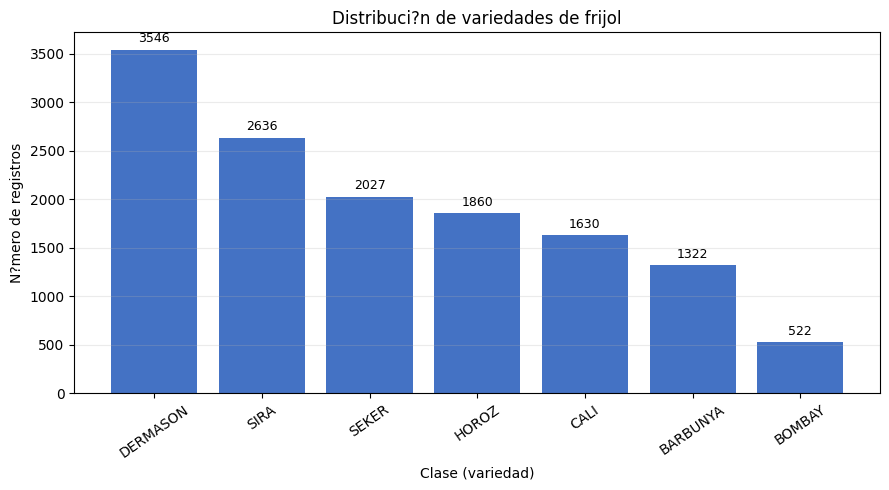

In [4]:
df_clean = df.drop_duplicates().copy()
class_counts = df_clean["Class"].value_counts()
class_ratio = float(class_counts.max() / class_counts.min())

print(f"Filas despu?s de retirar duplicados: {len(df_clean):,}")
print(f"Clases: {len(class_counts)}")
print(f"Raz?n clase m?s frecuente / menos frecuente: {class_ratio:.2f}")
display(class_counts.rename("cantidad").to_frame())

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(class_counts.index, class_counts.values, color="#4472C4")
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_title("Distribuci?n de variedades de frijol")
ax.set_xlabel("Clase (variedad)")
ax.set_ylabel("N?mero de registros")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(REPORTS_DIR / "distribucion_clases.png", dpi=150, bbox_inches="tight")
plt.show()

### EDA ? Distribuci?n de las medidas

Los histogramas permiten comparar la forma de algunas variables geom?tricas. Por ejemplo, el ?rea suele tener una escala y asimetr?a diferentes a las razones de forma; esto justifica revisar estad?sticas antes de elegir transformaciones o modelos.

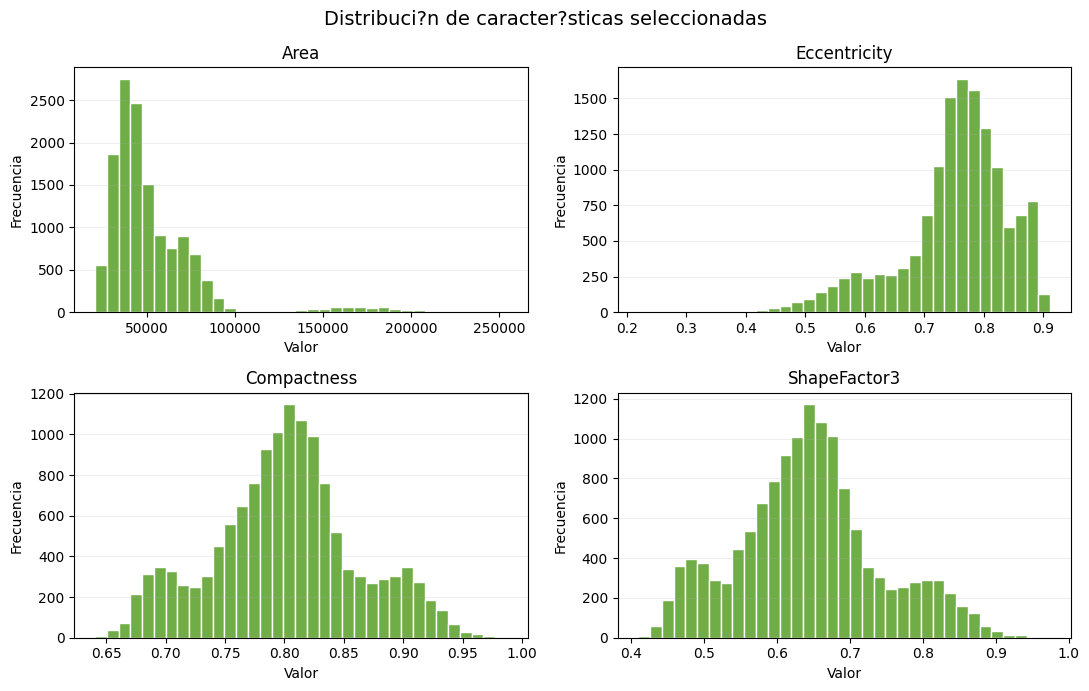

In [5]:
hist_features = ["Area", "Eccentricity", "Compactness", "ShapeFactor3"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for feature, ax in zip(hist_features, axes.ravel()):
    ax.hist(df_clean[feature], bins=35, color="#70AD47", edgecolor="white")
    ax.set_title(feature)
    ax.set_xlabel("Valor")
    ax.set_ylabel("Frecuencia")
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Distribuci?n de caracter?sticas seleccionadas", fontsize=14)
fig.tight_layout()
fig.savefig(REPORTS_DIR / "distribucion_caracteristicas.png", dpi=150, bbox_inches="tight")
plt.show()

### EDA ? Correlaci?n entre caracter?sticas

El mapa de calor muestra correlaciones lineales entre algunas medidas de tama?o y forma. Correlaci?n no significa causalidad; las variables geom?tricas relacionadas pueden aportar informaci?n redundante y deben interpretarse junto con el contexto del problema.

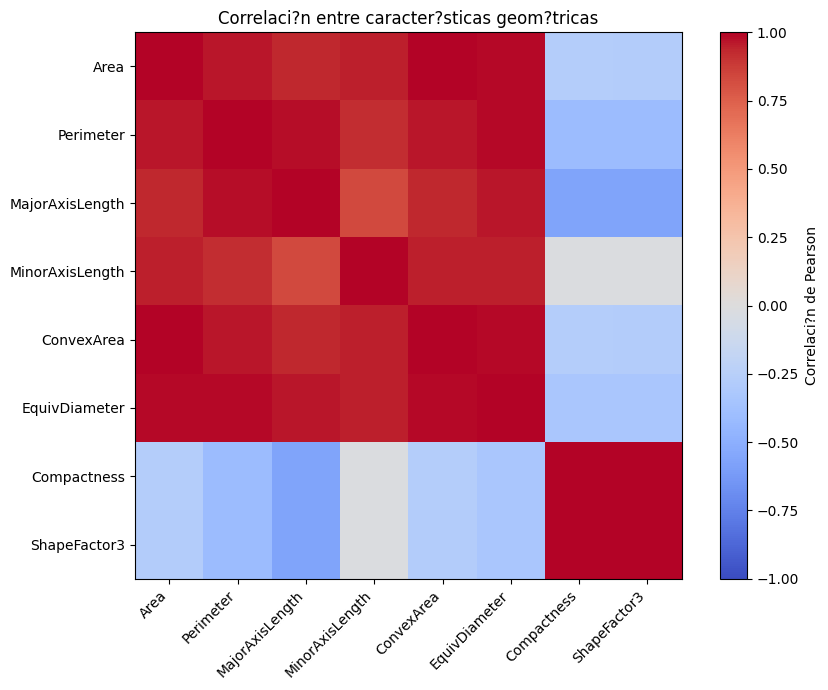

In [6]:
correlation_features = [
    "Area", "Perimeter", "MajorAxisLength", "MinorAxisLength",
    "ConvexArea", "EquivDiameter", "Compactness", "ShapeFactor3",
]
correlation = df_clean[correlation_features].corr()

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation_features)), labels=correlation_features, rotation=45, ha="right")
ax.set_yticks(range(len(correlation_features)), labels=correlation_features)
ax.set_title("Correlaci?n entre caracter?sticas geom?tricas")
fig.colorbar(image, ax=ax, label="Correlaci?n de Pearson")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "correlacion_caracteristicas.png", dpi=150, bbox_inches="tight")
plt.show()

## Paso 4 ? Separar predictores y objetivo

`X` contiene las 16 medidas geom?tricas; `y` contiene la etiqueta `Class`. La partici?n 80/20 reserva datos no vistos para la evaluaci?n. `stratify=y` mantiene aproximadamente la misma proporci?n de variedades en entrenamiento y prueba.

In [7]:
X = df_clean.drop(columns="Class")
y = df_clean["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Entrenamiento: {len(X_train):,} filas")
print(f"Prueba: {len(X_test):,} filas")
print(f"Predictoras: {X_train.shape[1]}")

Entrenamiento: 10,834 filas
Prueba: 2,709 filas
Predictoras: 16


## Paso 5 ? Entrenar el baseline: regresi?n log?stica

El baseline proporciona una referencia sencilla para juzgar modelos m?s complejos. Estandarizamos las variables dentro de un `Pipeline`, de modo que el escalamiento se ajuste solo con los datos de entrenamiento y no filtre informaci?n del conjunto de prueba.

In [8]:
baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
)
baseline_model.fit(X_train, y_train)
y_pred_baseline = baseline_model.predict(X_test)

baseline_metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred_baseline)),
    "f1_macro": float(f1_score(y_test, y_pred_baseline, average="macro")),
}
print(f"Accuracy baseline: {baseline_metrics['accuracy']:.4f}")
print(f"F1 macro baseline: {baseline_metrics['f1_macro']:.4f}")
print("Reporte por clase:")
display(pd.DataFrame(classification_report(
    y_test, y_pred_baseline, output_dict=True, zero_division=0
)).T.round(3))

Accuracy baseline: 0.9192
F1 macro baseline: 0.9302
Reporte por clase:


,precision,recall,f1-score,support
BARBUNYA,0.925,0.891,0.908,265.000
BOMBAY,1.000,1.000,1.000,104.000
CALI,0.911,0.942,0.926,326.000
DERMASON,0.927,0.907,0.917,709.000
HOROZ,0.964,0.944,0.954,372.000
SEKER,0.930,0.943,0.936,406.000
SIRA,0.858,0.884,0.871,527.000
accuracy,0.919,0.919,0.919,0.919
macro avg,0.931,0.930,0.930,2709.000
weighted avg,0.920,0.919,0.919,2709.000


## Paso 6 ? Entrenar el modelo alternativo: Random Forest

Random Forest combina muchos ?rboles de decisi?n y no necesita estandarizaci?n. Se fija la semilla para reproducir el experimento y se usa `class_weight="balanced"` como apoyo ante diferencias en la frecuencia de clases.

In [9]:
forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    class_weight="balanced",
    n_jobs=-1,
)
forest_model.fit(X_train, y_train)
y_pred_forest = forest_model.predict(X_test)

forest_metrics = {
    "accuracy": float(accuracy_score(y_test, y_pred_forest)),
    "f1_macro": float(f1_score(y_test, y_pred_forest, average="macro")),
}
metrics = {
    "Regresi?n log?stica (baseline)": baseline_metrics,
    "Random Forest": forest_metrics,
}
metrics_table = pd.DataFrame(metrics).T
display(metrics_table.round(4))
print(
    "Diferencia de F1 macro (Random Forest - baseline): "
    f"{forest_metrics['f1_macro'] - baseline_metrics['f1_macro']:+.4f}"
)

,accuracy,f1_macro
Regresi?n log?stica (baseline),0.9192,0.9302
Random Forest,0.9192,0.9303


Diferencia de F1 macro (Random Forest - baseline): +0.0001


## Paso 7 ? Evaluar errores con la matriz de confusi?n

La diagonal representa predicciones correctas; las celdas fuera de ella muestran confusiones entre variedades. Revisaremos el par con mayor suma de errores mutuos. La gr?fica describe esta partici?n de prueba, no demuestra por s? sola el motivo f?sico de la confusi?n.

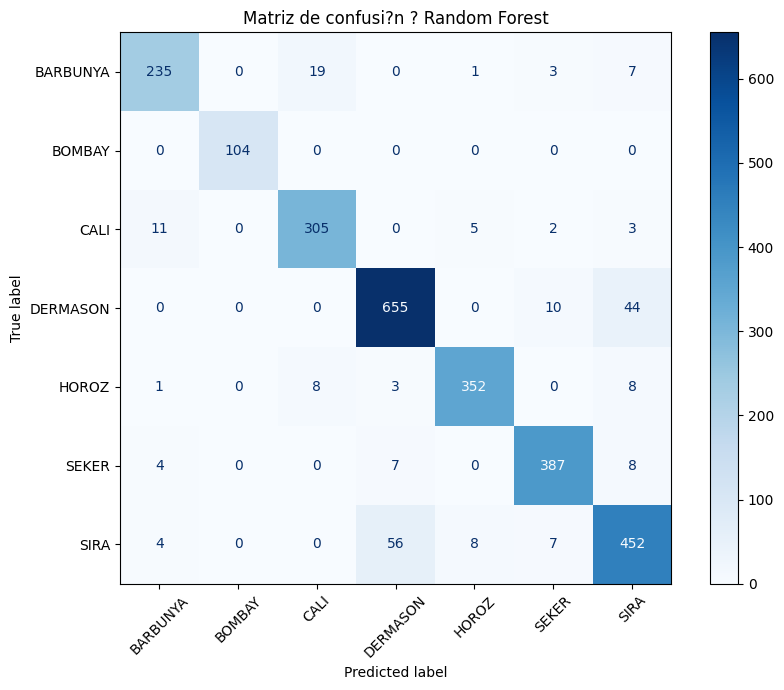

Par con m?s confusiones mutuas: DERMASON y SIRA (100 errores sumados en ambas direcciones).


In [10]:
class_labels = sorted(y.unique())
confusion = confusion_matrix(y_test, y_pred_forest, labels=class_labels)

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_forest,
    labels=class_labels,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax,
)
ax.set_title("Matriz de confusi?n ? Random Forest")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "matriz_confusion_random_forest.png", dpi=150, bbox_inches="tight")
plt.show()

errors = confusion.copy()
np.fill_diagonal(errors, 0)
mutual_errors = errors + errors.T
np.fill_diagonal(mutual_errors, 0)
row, column = np.unravel_index(np.argmax(mutual_errors), mutual_errors.shape)
print(
    f"Par con m?s confusiones mutuas: {class_labels[row]} y {class_labels[column]} "
    f"({mutual_errors[row, column]} errores sumados en ambas direcciones)."
)

## Paso 8 ? Interpretar la importancia de variables

Random Forest estima cu?nto contribuye cada variable a sus divisiones. La importancia ayuda a describir el modelo, pero **no** prueba que una medida cause la variedad. Contrastarla con conocimiento del dominio y con otros an?lisis antes de sacar conclusiones.

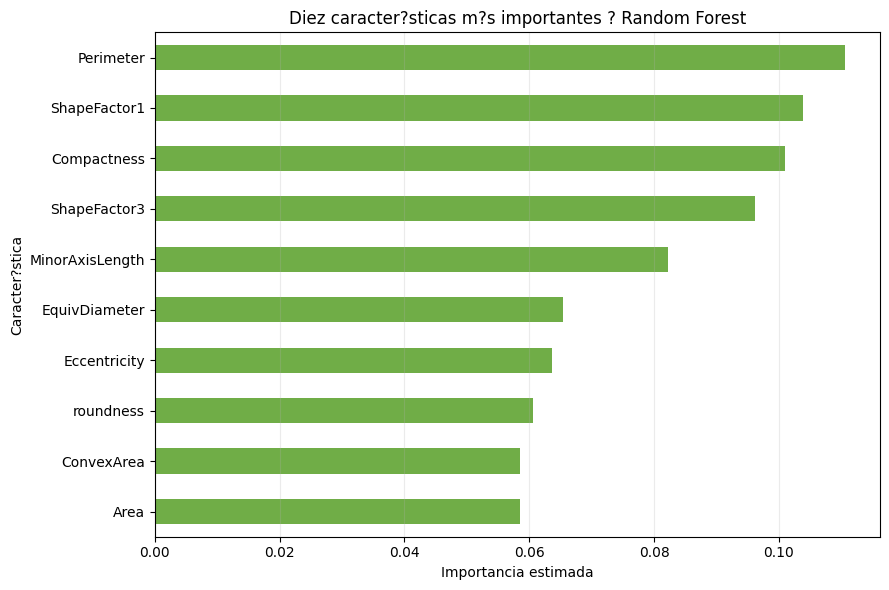

,caracter?stica,importancia
1,Perimeter,0.1107
12,ShapeFactor1,0.1038
11,Compactness,0.1010
14,ShapeFactor3,0.0962
3,MinorAxisLength,0.0823
7,EquivDiameter,0.0654
5,Eccentricity,0.0636
10,roundness,0.0606
6,ConvexArea,0.0585
0,Area,0.0584


In [11]:
feature_importance = pd.DataFrame({
    "caracter?stica": X.columns,
    "importancia": forest_model.feature_importances_,
}).sort_values("importancia", ascending=False)

top_features = feature_importance.head(10).sort_values("importancia")
ax = top_features.plot(
    x="caracter?stica",
    y="importancia",
    kind="barh",
    legend=False,
    figsize=(9, 6),
    color="#70AD47",
)
ax.set_title("Diez caracter?sticas m?s importantes ? Random Forest")
ax.set_xlabel("Importancia estimada")
ax.set_ylabel("Caracter?stica")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "importancia_variables.png", dpi=150, bbox_inches="tight")
plt.show()
display(feature_importance.head(10).round(4))

## Paso 9 ? Seleccionar, guardar y probar el modelo

Seleccionamos por F1 macro, guardamos el artefacto con `joblib`, lo volvemos a cargar y pedimos una predicci?n de prueba. Este es un despliegue local m?nimo: demuestra que el objeto guardado puede reutilizarse, pero no equivale a poner un servicio en producci?n.

In [12]:
models = {
    "Regresi?n log?stica (baseline)": baseline_model,
    "Random Forest": forest_model,
}
best_name = max(metrics, key=lambda model_name: metrics[model_name]["f1_macro"])
best_model = models[best_name]
model_path = MODELS_DIR / "modelo_final_drybean.joblib"
joblib.dump(best_model, model_path)

loaded_model = joblib.load(model_path)
sample = X_test.iloc[[0]]
prediction = loaded_model.predict(sample)[0]
actual = y_test.iloc[0]

metrics_path = REPORTS_DIR / "metricas_notebook.json"
metrics_path.write_text(
    json.dumps(metrics, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(f"Modelo seleccionado por F1 macro: {best_name}")
print(f"Artefacto guardado en: {model_path.relative_to(PROJECT_ROOT)}")
print(f"Predicci?n de ejemplo: {prediction}; clase real: {actual}")
print(f"La predicci?n fue {'correcta' if prediction == actual else 'incorrecta'}.")

Modelo seleccionado por F1 macro: Random Forest
Artefacto guardado en: outputs\models\modelo_final_drybean.joblib
Predicci?n de ejemplo: SEKER; clase real: SEKER
La predicci?n fue correcta.


## Conclusiones para explicar

- El conjunto original contiene **13.611 registros**, **16 caracter?sticas predictoras** y **7 clases**; `Class` es el objetivo.
- Se encontraron **68 filas duplicadas** y ning?n valor faltante. Despu?s de depurar quedaron **13.543 registros**.
- Las clases no son perfectamente balanceadas; F1 macro ayuda a revisar el desempe?o dando el mismo peso a cada variedad.
- En esta ejecuci?n, la regresi?n log?stica obtuvo Accuracy **0,9192** y F1 macro **0,9302**. Random Forest obtuvo Accuracy **0,9192** y F1 macro **0,9303**.
- La mejora de F1 macro de Random Forest es peque?a (aproximadamente **0,0001**). Por eso se selecciona provisionalmente por F1 macro, pero conviene contrastarlo con validaci?n cruzada y con los costos de error del negocio.
- DERMASON y SIRA presentaron las confusiones mutuas m?s altas en la partici?n de prueba. Las medidas geom?tricas pueden solaparse; esa explicaci?n debe verificarse, no asumirse como causalidad.

### Guion sugerido para la exposici?n

1. **Sergio ? Producto y problema:** explique la necesidad de apoyar el control de calidad y qu? significa predecir `Class`.
2. **Dilmer ? Datos y EDA:** presente la fuente UCI, las 16 medidas, los faltantes, duplicados, balance de clases e histogramas.
3. **Luis ? Proceso del equipo:** relacione las fases CRISP-DM con los sprints Scrum ML y explique c?mo TDSP ordena los artefactos.
4. **Andres ? Baseline:** explique la partici?n reproducible, el pipeline con escalamiento y por qu? la regresi?n log?stica sirve como referencia.
5. **Eliana ? Modelo y evaluaci?n:** muestre Random Forest, comparaci?n de m?tricas, matriz de confusi?n e importancia de variables.
6. **Cierre conjunto:** interpreten la mejora peque?a, mencionen limitaciones y propongan validar con m?s experimentos antes de producci?n.

> Este guion es una propuesta para preparar la presentaci?n. El equipo debe validar la interpretaci?n y completar la evidencia Scrum con sus avances reales.